# 05 — K-Means clustering: applicant risk segments

Unsupervised segmentation of the training applicants on eight profile features, to see whether natural groups of
applicants exist and how their default rates differ:

1. Features: `AGE_YEARS`, log of `AMT_INCOME_TOTAL`, `CREDIT_INCOME_RATIO`, `ANNUITY_INCOME_RATIO`, `YEARS_EMPLOYED`,
   `EXT_SOURCE_MEAN`, `INST_LATE_SHARE` (share of previous instalments paid late) and `PREV_REFUSED_SHARE` (share of
   previous applications refused).
2. Number of clusters *k* chosen with the elbow method (k = 2–10) and the silhouette score (20,000-applicant sample).
3. Cluster sizes, mean profiles, standardised centres, default rate per cluster, and a risk-segment name per cluster.
4. A 2-D picture of the clusters (2-component PCA, used only for plotting).
5. Does the cluster label help LightGBM?

`TARGET` is **not** used to build the clusters; default rates are only looked at afterwards.
**Leakage controls:** imputation, scaling and K-Means are fitted on the **training set only**
(`data/processed/split_ids.parquet`); holdout applicants are only assigned to the fitted centres. The holdout is
evaluated once, for the LightGBM + cluster model. Shared code: `src/clustering.py`, `src/modeling.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, silhouette_score

from src.clustering import CLUSTER_FEATURES, cluster_frame, make_cluster_scaler, make_kmeans
from src.config import ID, MODELS_DIR, PROCESSED_DIR, RANDOM_STATE, REPORTS_DIR, TARGET
from src.modeling import (categorical_columns, cross_validate_gbm, feature_columns, fit_lgbm, load_or_create_split,
                          train_holdout)
from src.plotting import INK_2, MUTED, SERIES, savefig, set_style

set_style()
pd.set_option("display.max_columns", 40, "display.width", 180)
MODELS_OUT, PROCESSED_OUT = MODELS_DIR, PROCESSED_DIR  # where this notebook writes

model_table = pd.read_parquet(PROCESSED_DIR / "model_table.parquet")
split, created = load_or_create_split(model_table)
assert not created, "split must come from notebook 03"
train, holdout = train_holdout(model_table, split)
FEATURES = feature_columns(model_table)
X_train, y_train = train[FEATURES], train[TARGET]
X_holdout, y_holdout = holdout[FEATURES], holdout[TARGET]
SMOKE_FRAC = 1.0
print(f"train {len(train):,} | holdout {len(holdout):,}")

train 246,005 | holdout 61,502


## 1. Clustering features and preprocessing

**How K-Means works:** choose *k* centres, assign every applicant to the nearest centre, move each centre to the mean
of its applicants, and repeat until nothing changes. It minimises the within-cluster sum of squared distances
(*inertia*). `n_init=10` restarts with different starting centres, `random_state=42`.

**Preprocessing (fitted on train):** income enters as its logarithm because it is extremely right-skewed. Median
imputation fills the gaps (pensioners have no `YEARS_EMPLOYED`; applicants without Home Credit history have no
`INST_`/`PREV_` shares), and `StandardScaler` puts every feature on the same scale, because K-Means uses Euclidean
distance and would otherwise be dominated by the feature with the largest units.

In [2]:
cf_train, cf_holdout = cluster_frame(train), cluster_frame(holdout)
display(pd.DataFrame({"missing_share": cf_train.isna().mean(), "mean": cf_train.mean(), "median": cf_train.median(),
                      "std": cf_train.std()}).round(4))
cluster_scaler = make_cluster_scaler().fit(cf_train)
Z_train, Z_holdout = cluster_scaler.transform(cf_train), cluster_scaler.transform(cf_holdout)
print(f"standardised training matrix: {Z_train.shape[0]:,} applicants x {Z_train.shape[1]} features")

,missing_share,mean,median,std
AGE_YEARS,0.0000,43.9275,43.1425,11.9566
LOG_INCOME,0.0000,11.9094,11.8878,0.4895
CREDIT_INCOME_RATIO,0.0000,3.9527,3.2586,2.6847
ANNUITY_INCOME_RATIO,0.0000,0.1808,0.1627,0.0946
YEARS_EMPLOYED,0.1798,6.5374,4.5205,6.4119
EXT_SOURCE_MEAN,0.0006,0.5091,0.5243,0.1499
INST_LATE_SHARE,0.0515,0.0860,0.0189,0.1416
PREV_REFUSED_SHARE,0.0535,0.1107,0.0000,0.1842


standardised training matrix: 246,005 applicants x 8 features


## 2. Choosing k: elbow method and silhouette score

- **Elbow:** inertia always falls as *k* grows; the "elbow" is where adding another cluster stops buying much.
- **Silhouette** (−1 to 1): how much closer each applicant is to its own cluster than to the next one, computed on a
  random sample of 20,000 training applicants (it needs all pairwise distances).

,inertia,silhouette_20k_sample,smallest_cluster,default_rate_min,default_rate_max,inertia_drop
k,,,,,,
2,1.657544e+06,0.1755,77053,0.0725,0.0845,NaN
3,1.471048e+06,0.1426,53708,0.0401,0.1300,186496.2991
4,1.338023e+06,0.1464,37249,0.0371,0.1324,133024.5156
5,1.220832e+06,0.1548,19253,0.0361,0.1284,117190.7751
6,1.112875e+06,0.1634,18330,0.0381,0.1327,107957.6349
7,1.036637e+06,0.1532,17008,0.0395,0.1327,76237.7729
8,9.906816e+05,0.1462,15781,0.0393,0.1343,45955.2121
9,9.561145e+05,0.1296,12602,0.0393,0.1805,34567.0972
10,9.253664e+05,0.1297,10280,0.0381,0.1643,30748.1279


chosen k = 6: silhouette 0.1634 (k = 2: 0.1755, default rates 7.25% vs 8.45%); inertia drop to k = 6: 107,958, to k = 7: 76,238


saved reports/figures/39_kmeans_elbow_silhouette.png


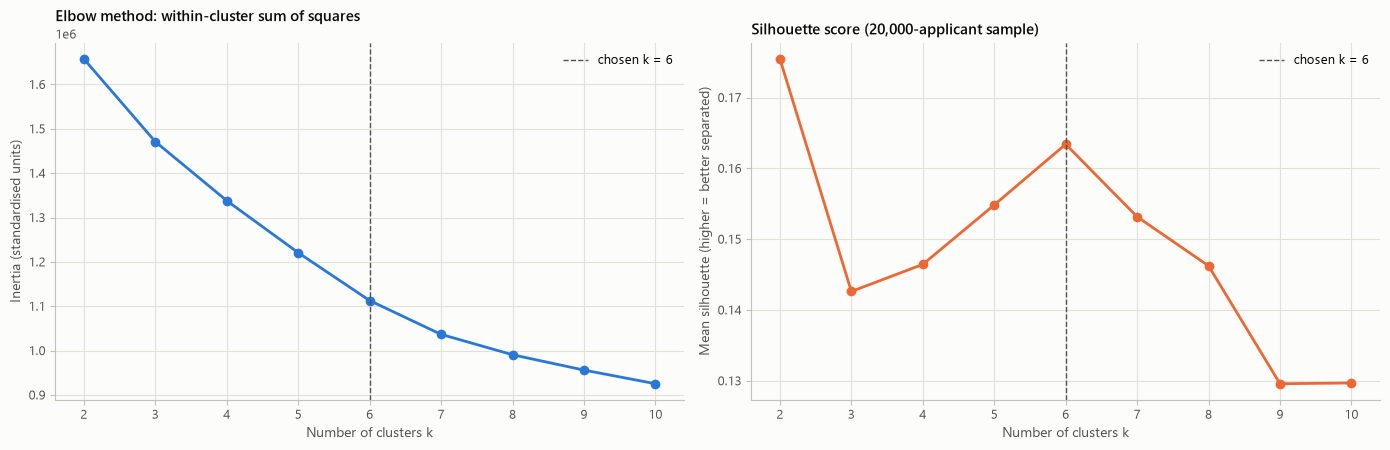

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
sil_idx = rng.choice(len(Z_train), size=min(20_000, len(Z_train)), replace=False)
k_rows, kmeans_fits = [], {}
for k in range(2, 11):
    km = make_kmeans(k).fit(Z_train)
    kmeans_fits[k] = km
    rates = pd.Series(y_train.to_numpy()).groupby(km.labels_).mean()
    k_rows.append({"k": k, "inertia": km.inertia_,
                   "silhouette_20k_sample": silhouette_score(Z_train[sil_idx], km.labels_[sil_idx]),
                   "smallest_cluster": int(np.bincount(km.labels_).min()),
                   "default_rate_min": rates.min(), "default_rate_max": rates.max()})
k_table = pd.DataFrame(k_rows).set_index("k")
k_table["inertia_drop"] = -k_table["inertia"].diff()
display(k_table.round(4))

# Choice: the best silhouette among k >= 3 (k = 2 only splits applicants into two broad halves with similar default
# rates, see the table), checked against the elbow of the inertia curve.
K = int(k_table.loc[3:, "silhouette_20k_sample"].idxmax())
print(f"chosen k = {K}: silhouette {k_table.loc[K, 'silhouette_20k_sample']:.4f} (k = 2: "
      f"{k_table.loc[2, 'silhouette_20k_sample']:.4f}, default rates {k_table.loc[2, 'default_rate_min']:.2%} vs "
      f"{k_table.loc[2, 'default_rate_max']:.2%}); inertia drop to k = {K}: {k_table.loc[K, 'inertia_drop']:,.0f}, "
      f"to k = {K + 1}: {k_table.loc[K + 1, 'inertia_drop']:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(k_table.index, k_table["inertia"], marker="o", color=SERIES[0])
axes[0].axvline(K, color=INK_2, linestyle="--", linewidth=1, label=f"chosen k = {K}")
axes[0].set_title("Elbow method: within-cluster sum of squares", loc="left", fontsize=11)
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (standardised units)")
axes[0].legend(loc="upper right")
axes[1].plot(k_table.index, k_table["silhouette_20k_sample"], marker="o", color=SERIES[1])
axes[1].axvline(K, color=INK_2, linestyle="--", linewidth=1, label=f"chosen k = {K}")
axes[1].set_title(f"Silhouette score ({len(sil_idx):,}-applicant sample)", loc="left", fontsize=11)
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Mean silhouette (higher = better separated)")
axes[1].legend(loc="upper right")
fig.tight_layout()
savefig(fig, "39_kmeans_elbow_silhouette.png")
plt.show()

**Insight:** The silhouette score is highest at k = 2 (0.1755), but those two halves default at 7.25% and 8.45%, too similar to be
useful risk segments. Among k ≥ 3 the best silhouette is at **k = 6** (0.1634), which is also where the elbow curve
bends: adding the 6th cluster still reduces inertia by 107,958, the 7th by only 76,238 and the 8th by 45,955. All
silhouette values are low (0.1296–0.1755), so applicants form overlapping groups rather than sharply separated ones.

## 3. Cluster profiles and risk-segment names

Each cluster is named after the feature whose standardised centre is most extreme for it (rules in the code, checked
to give one name per cluster). The risk level compares the cluster's training default rate with the overall rate:
**low** below 0.8×, **high** above 1.2×, otherwise **medium**. Holdout applicants are assigned to the nearest
training centre to check that the differences hold on unseen applicants.

In [4]:
kmeans = kmeans_fits[K]
labels_train, labels_holdout = kmeans.labels_, kmeans.predict(Z_holdout)
centres = pd.DataFrame(kmeans.cluster_centers_, columns=CLUSTER_FEATURES)

NAME_RULES = [("Frequent late payers", "INST_LATE_SHARE", "max"),
              ("Often refused before", "PREV_REFUSED_SHARE", "max"),
              ("High loan-to-income borrowers", "CREDIT_INCOME_RATIO", "max"),
              ("Long-tenure employees", "YEARS_EMPLOYED", "max"),
              ("Young, early-career applicants", "AGE_YEARS", "min"),
              ("Older applicants with strong external scores", "AGE_YEARS", "max")]
segment = {}
for name, feat, how in NAME_RULES:
    free = centres.drop(index=list(segment))
    if free.empty:
        break
    cid = int(free[feat].idxmax() if how == "max" else free[feat].idxmin())
    segment[cid] = name
for cid in centres.index.difference(list(segment)):
    segment[int(cid)] = f"Cluster {cid}"
assert len(set(segment.values())) == K

overall = y_train.mean()
profile = cf_train.assign(TARGET=y_train.to_numpy(), cluster=labels_train).groupby("cluster").agg(
    applicants=("TARGET", "size"), default_rate=("TARGET", "mean"),
    **{f"mean_{c}": (c, "mean") for c in CLUSTER_FEATURES})
profile["share"] = profile["applicants"] / profile["applicants"].sum()
holdout_rates = pd.Series(y_holdout.to_numpy()).groupby(labels_holdout).agg(["size", "mean"])
profile["holdout_applicants"] = holdout_rates["size"]
profile["holdout_default_rate"] = holdout_rates["mean"]
profile["risk_level"] = np.select([profile["default_rate"] < 0.8 * overall, profile["default_rate"] > 1.2 * overall],
                                  ["low", "high"], "medium")
profile["segment"] = [f"{segment[c]} ({r} risk)" for c, r in zip(profile.index, profile["risk_level"])]
profile = profile.sort_values("default_rate")
order = profile.index.tolist()
print(f"overall training default rate: {overall:.2%}")
display(profile[["segment", "applicants", "share", "default_rate", "holdout_applicants", "holdout_default_rate"]]
        .style.format({"applicants": "{:,}", "share": "{:.1%}", "default_rate": "{:.2%}",
                       "holdout_applicants": "{:,}", "holdout_default_rate": "{:.2%}"}))
print("mean profile of each cluster (original units; missing values ignored, so YEARS_EMPLOYED excludes pensioners):")
display(profile.set_index("segment")[[f"mean_{c}" for c in CLUSTER_FEATURES]]
        .rename(columns=lambda c: c.replace("mean_", "")).round(3))

overall training default rate: 8.07%


,segment,applicants,share,default_rate,holdout_applicants,holdout_default_rate
cluster,,,,,,
5,Long-tenure employees (low risk),"20,938",8.5%,3.81%,"5,246",4.10%
4,Older applicants with strong external scores (low risk),"66,471",27.0%,4.00%,"16,482",4.11%
3,High loan-to-income borrowers (medium risk),"38,227",15.5%,7.23%,"9,649",6.66%
0,"Young, early-career applicants (high risk)","69,644",28.3%,10.07%,"17,433",10.19%
1,Frequent late payers (high risk),"18,330",7.5%,12.70%,"4,527",12.86%
2,Often refused before (high risk),"32,395",13.2%,13.27%,"8,165",13.12%


mean profile of each cluster (original units; missing values ignored, so YEARS_EMPLOYED excludes pensioners):


,AGE_YEARS,LOG_INCOME,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,YEARS_EMPLOYED,EXT_SOURCE_MEAN,INST_LATE_SHARE,PREV_REFUSED_SHARE
segment,,,,,,,,
Long-tenure employees (low risk),48.293,12.049,3.816,0.166,20.732,0.569,0.061,0.076
Older applicants with strong external scores (low risk),53.766,11.961,3.206,0.151,5.301,0.597,0.045,0.048
High loan-to-income borrowers (medium risk),46.452,11.515,8.244,0.329,5.926,0.525,0.058,0.060
"Young, early-career applicants (high risk)",33.414,11.998,2.896,0.146,4.072,0.435,0.049,0.034
Frequent late payers (high risk),42.508,11.891,3.431,0.174,5.567,0.476,0.461,0.112
Often refused before (high risk),41.344,11.999,3.076,0.157,4.918,0.450,0.073,0.461


saved reports/figures/40_kmeans_cluster_heatmap.png


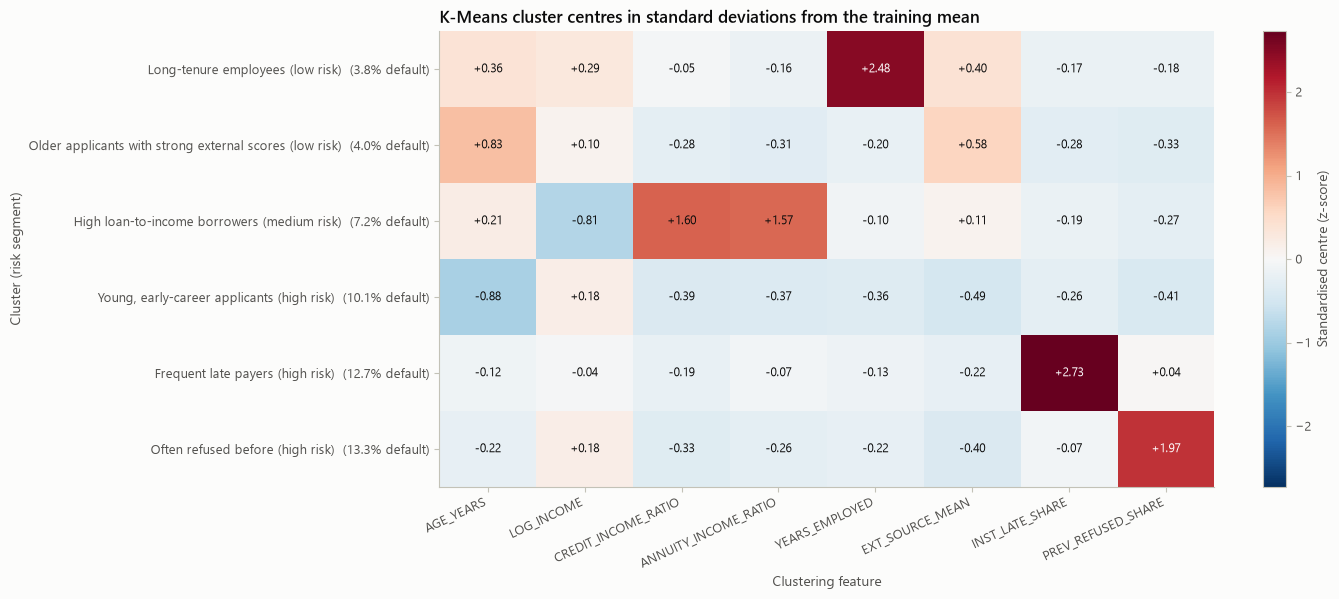

In [5]:
heat = centres.loc[order]
fig, ax = plt.subplots(figsize=(12.5, 0.62 * K + 2.2))
vmax = np.abs(heat.to_numpy()).max()
im = ax.imshow(heat.to_numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
for (r, c), v in np.ndenumerate(heat.to_numpy()):
    ax.text(c, r, f"{v:+.2f}", ha="center", va="center", fontsize=8.5,
            color="white" if abs(v) > 0.6 * vmax else "#0b0b0b")
ax.set_xticks(range(len(CLUSTER_FEATURES)), CLUSTER_FEATURES, rotation=25, ha="right")
ax.set_yticks(range(K), [f"{profile.loc[c, 'segment']}  ({profile.loc[c, 'default_rate']:.1%} default)" for c in order])
ax.set_xlabel("Clustering feature")
ax.set_ylabel("Cluster (risk segment)")
ax.set_title("K-Means cluster centres in standard deviations from the training mean", loc="left")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Standardised centre (z-score)")
savefig(fig, "40_kmeans_cluster_heatmap.png")
plt.show()

**Insight:** Each segment is defined by one or two features: frequent late payers (`INST_LATE_SHARE` +2.73 standard deviations),
often refused before (`PREV_REFUSED_SHARE` +1.97), long-tenure employees (`YEARS_EMPLOYED` +2.48), high loan-to-income
borrowers (credit/income +1.60, annuity/income +1.57, with income −0.81), older applicants with strong external
scores (age +0.83, `EXT_SOURCE_MEAN` +0.58) and young, early-career applicants (age −0.88, `EXT_SOURCE_MEAN` −0.49).

saved reports/figures/41_kmeans_default_rate.png


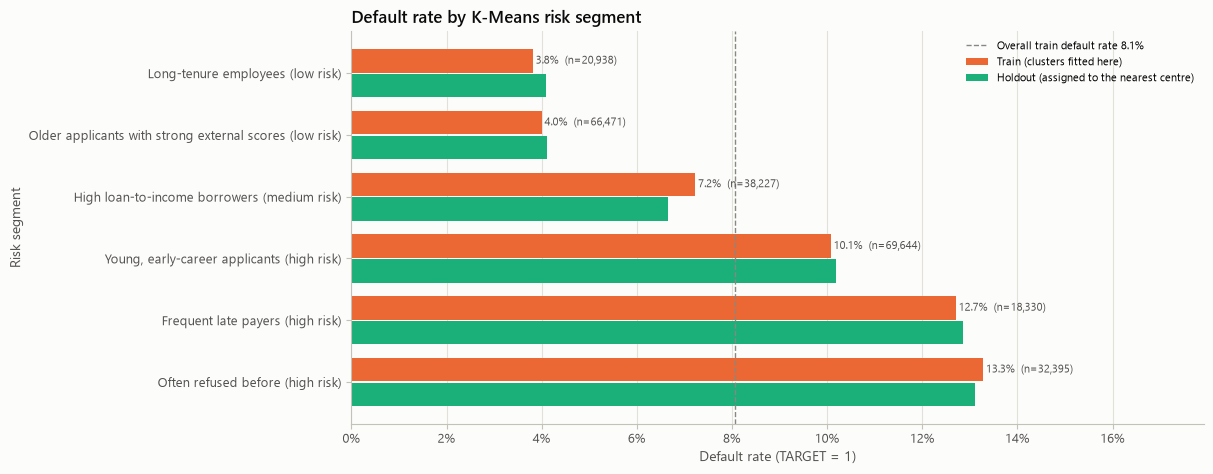

In [6]:
fig, ax = plt.subplots(figsize=(11, 0.55 * K + 1.8))
y_pos = np.arange(K)
ax.barh(y_pos - 0.2, profile["default_rate"], height=0.38, color=SERIES[1], label="Train (clusters fitted here)")
ax.barh(y_pos + 0.2, profile["holdout_default_rate"], height=0.38, color=SERIES[2],
        label="Holdout (assigned to the nearest centre)")
for yp, (r, n) in enumerate(zip(profile["default_rate"], profile["applicants"])):
    ax.text(r, yp - 0.2, f" {r:.1%}  (n={n:,})", va="center", fontsize=8, color=INK_2)
ax.axvline(overall, color=MUTED, linestyle="--", linewidth=1, label=f"Overall train default rate {overall:.1%}")
ax.set_yticks(y_pos, profile["segment"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, profile[["default_rate", "holdout_default_rate"]].to_numpy().max() * 1.35)
ax.set_title("Default rate by K-Means risk segment", loc="left")
ax.set_xlabel("Default rate (TARGET = 1)")
ax.set_ylabel("Risk segment")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", fontsize=8)
savefig(fig, "41_kmeans_default_rate.png")
plt.show()

**Insight:** Default rates range from 3.81% (long-tenure employees, 20,938 applicants) and 4.00% (older applicants with strong
external scores, the second-largest group with 66,471) to 12.70% (frequent late payers) and 13.27% (often refused
before), against 8.07% overall. The young, early-career segment is the largest (69,644, 28.3%) and defaults at
10.07%. Holdout applicants assigned to the same centres differ by at most 0.56 percentage points, so the segments
generalise. High loan-to-income borrowers default *below* average (7.23%), consistent with the weak affordability
signal in the EDA.

## 4. The clusters in two dimensions

The clusters live in 8 dimensions, so two 2-D views of 10,000 random training applicants are shown:
- **left:** a 2-component PCA fitted on the standardised training features **for plotting only** (not used for
  clustering or modelling); it shows the directions of largest overall variation;
- **right:** the two features that separate the clusters most, i.e. with the largest between-cluster share of their
  (standardised) variance, sum over clusters of size × centre² / total size.

variance shown by the 2 plotting components: 44.1% (PC1 26.1%, PC2 18.0%)


,PC1,PC2
AGE_YEARS,0.188,0.515
LOG_INCOME,-0.420,0.227
CREDIT_INCOME_RATIO,0.607,-0.050
ANNUITY_INCOME_RATIO,0.627,-0.136
YEARS_EMPLOYED,0.058,0.454
EXT_SOURCE_MEAN,0.093,0.609
INST_LATE_SHARE,-0.030,-0.193
PREV_REFUSED_SHARE,-0.113,-0.221


between-cluster share of each standardised feature's variance:
INST_LATE_SHARE         0.604
PREV_REFUSED_SHARE      0.602
YEARS_EMPLOYED          0.582
CREDIT_INCOME_RATIO     0.480
ANNUITY_INCOME_RATIO    0.458
AGE_YEARS               0.428
EXT_SOURCE_MEAN         0.199
LOG_INCOME              0.125


saved reports/figures/42_kmeans_clusters_2d.png


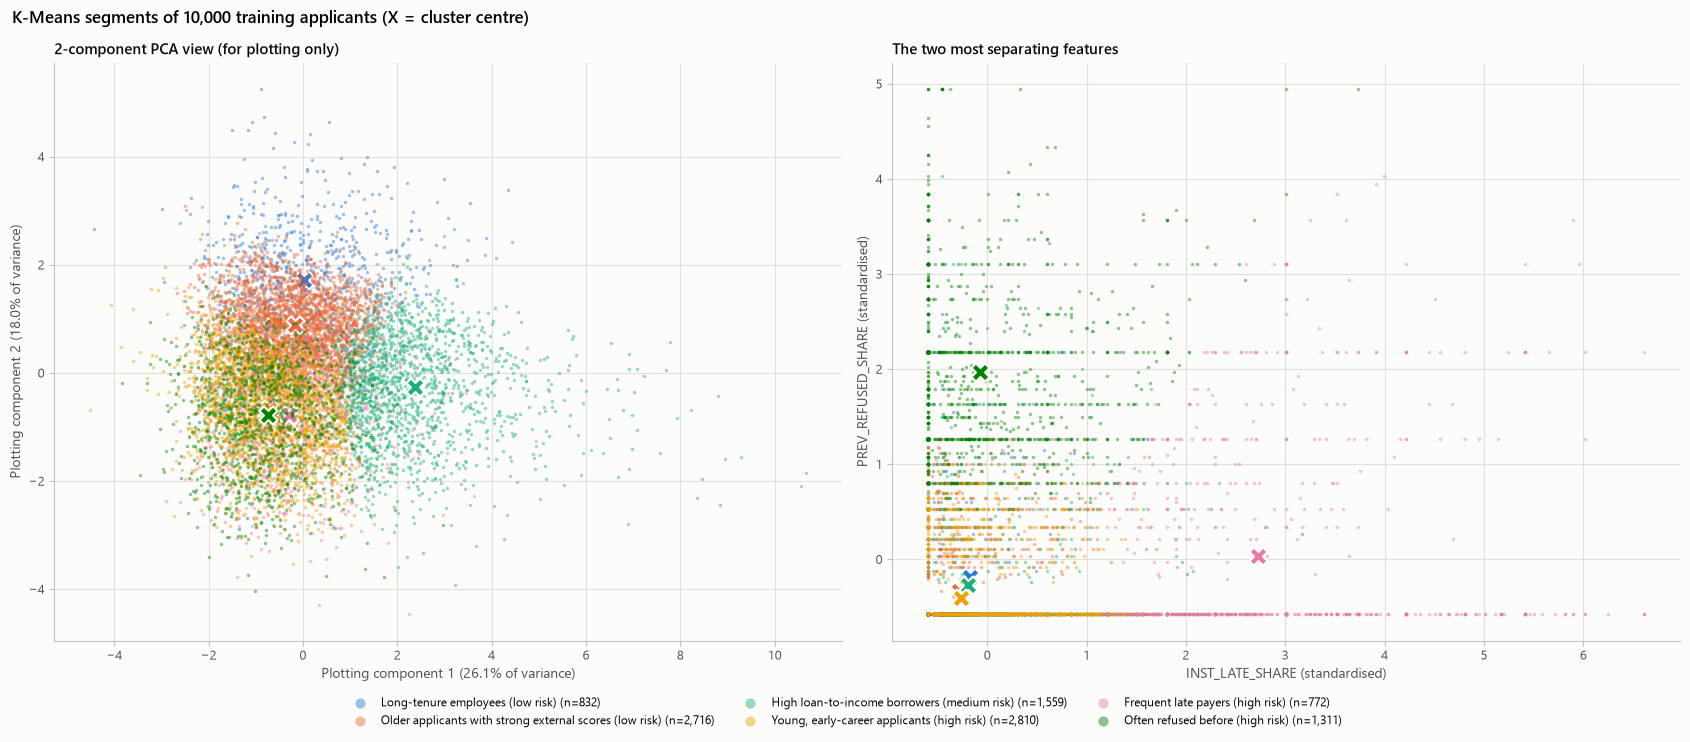

In [7]:
plot_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_train)
sample_pos = np.random.default_rng(RANDOM_STATE).choice(len(Z_train), size=min(10_000, len(Z_train)), replace=False)
xy = plot_pca.transform(Z_train[sample_pos])
sample_clusters = labels_train[sample_pos]
pc_loadings = pd.DataFrame(plot_pca.components_.T, index=CLUSTER_FEATURES, columns=["PC1", "PC2"])
print(f"variance shown by the 2 plotting components: {plot_pca.explained_variance_ratio_.sum():.1%} "
      f"(PC1 {plot_pca.explained_variance_ratio_[0]:.1%}, PC2 {plot_pca.explained_variance_ratio_[1]:.1%})")
display(pc_loadings.round(3))

separation = pd.Series((np.bincount(labels_train, minlength=K)[:, None] * kmeans.cluster_centers_ ** 2).sum(axis=0)
                       / len(labels_train), index=CLUSTER_FEATURES).sort_values(ascending=False)
f1, f2 = separation.index[:2]
print("between-cluster share of each standardised feature's variance:")
print(separation.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
centre_xy = plot_pca.transform(kmeans.cluster_centers_)
views = [(axes[0], xy[:, 0], xy[:, 1], centre_xy[:, 0], centre_xy[:, 1],
          f"Plotting component 1 ({plot_pca.explained_variance_ratio_[0]:.1%} of variance)",
          f"Plotting component 2 ({plot_pca.explained_variance_ratio_[1]:.1%} of variance)",
          "2-component PCA view (for plotting only)"),
         (axes[1], Z_train[sample_pos, CLUSTER_FEATURES.index(f1)], Z_train[sample_pos, CLUSTER_FEATURES.index(f2)],
          kmeans.cluster_centers_[:, CLUSTER_FEATURES.index(f1)], kmeans.cluster_centers_[:, CLUSTER_FEATURES.index(f2)],
          f"{f1} (standardised)", f"{f2} (standardised)", "The two most separating features")]
for ax, xs, ys, cx, cy, xlabel, ylabel, title in views:
    for k_i, cid in enumerate(order):
        mask = sample_clusters == cid
        ax.scatter(xs[mask], ys[mask], s=6, alpha=0.45, color=SERIES[k_i % len(SERIES)], linewidths=0,
                   label=f"{profile.loc[cid, 'segment']} (n={mask.sum():,})")
        ax.scatter(cx[cid], cy[cid], s=170, marker="X", color=SERIES[k_i % len(SERIES)], edgecolor="white",
                   linewidth=1.5)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8.5, markerscale=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"K-Means segments of {len(sample_pos):,} training applicants (X = cluster centre)", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
savefig(fig, "42_kmeans_clusters_2d.png")
plt.show()

**Insight:** The two PCA plotting components show 44.1% of the variance. Component 1 is loan size relative to income
(credit/income 0.607, annuity/income 0.627, log income −0.420) and separates the high loan-to-income segment;
component 2 is age, tenure and external score (0.515, 0.454, 0.609) and separates long-tenure and older applicants
from young ones. The two behavioural segments overlap with the young applicants in that view, but the two most
separating features, `INST_LATE_SHARE` and `PREV_REFUSED_SHARE` (between-cluster share 0.604 and 0.602 of their
variance), pull them apart clearly in the right panel.

## 5. Does the cluster label help LightGBM?

The K-Means label is added as one extra categorical feature (`KMEANS_CLUSTER`) to the tuned LightGBM from notebook 03
(same parameters and early-stopping scheme), scored with 5-fold CV on train and once on the holdout, and compared
with the saved LightGBM. K-Means was fitted on the whole training set without `TARGET`, so the CV estimate carries a
small amount of unsupervised look-ahead; the holdout comparison is clean.

In [8]:
cfg = json.loads((MODELS_DIR / "lgbm_best_params.json").read_text())
best_params = cfg["params"]
cluster_dtype = pd.CategoricalDtype(list(range(K)))
train_c = X_train.assign(KMEANS_CLUSTER=pd.Series(labels_train, index=X_train.index).astype(cluster_dtype))
holdout_c = X_holdout.assign(KMEANS_CLUSTER=pd.Series(labels_holdout, index=X_holdout.index).astype(cluster_dtype))

cv_c = cross_validate_gbm(fit_lgbm, best_params, train_c, y_train)
lgbm_c = fit_lgbm(best_params, train_c, y_train)
p_c = lgbm_c.predict_proba(holdout_c)[:, 1]
if SMOKE_FRAC == 1:
    lgbm_base, cv_base_auc = joblib.load(MODELS_DIR / "lgbm_model.joblib"), cfg["cv_auc_mean"]
else:  # smoke test: refit the baseline on the sample
    lgbm_base = fit_lgbm(best_params, X_train, y_train)
    cv_base_auc = cross_validate_gbm(fit_lgbm, best_params, X_train, y_train)["auc_mean"]
p_base = lgbm_base.predict_proba(X_holdout)[:, 1]
cluster_experiment = pd.DataFrame({
    "LightGBM (notebook 03)": {"features": len(FEATURES), "CV_AUC_mean": cv_base_auc,
                               "holdout_AUC": roc_auc_score(y_holdout, p_base)},
    "LightGBM + KMEANS_CLUSTER": {"features": len(FEATURES) + 1, "CV_AUC_mean": cv_c["auc_mean"],
                                  "holdout_AUC": roc_auc_score(y_holdout, p_c)}}).T
cluster_experiment.index.name = "model"
display(cluster_experiment.round(4))
gain = pd.Series(lgbm_c.booster_.feature_importance("gain"), index=lgbm_c.booster_.feature_name())
print(f"holdout AUC change: {cluster_experiment['holdout_AUC'].diff().iloc[-1]:+.4f}; CV AUC change: "
      f"{cluster_experiment['CV_AUC_mean'].diff().iloc[-1]:+.4f}; KMEANS_CLUSTER gain rank "
      f"{int(gain.rank(ascending=False)['KMEANS_CLUSTER'])} of {len(gain)} "
      f"({gain['KMEANS_CLUSTER'] / gain.sum():.2%} of total gain)")

,features,CV_AUC_mean,holdout_AUC
model,,,
LightGBM (notebook 03),161.0,0.7758,0.7819
LightGBM + KMEANS_CLUSTER,162.0,0.7763,0.7813


holdout AUC change: -0.0006; CV AUC change: +0.0005; KMEANS_CLUSTER gain rank 6 of 162 (4.03% of total gain)


**Insight:** Adding the segment label does not improve LightGBM: CV AUC moves from 0.7758 to 0.7763 (+0.0005) and holdout AUC from
0.7819 to 0.7813 (−0.0006). The model does use the new feature (6th of 162 by gain, 4.03% of total gain), but it only
re-packages information the trees already get from the raw features, so it replaces splits rather than adding
signal. The segments are useful for describing and communicating risk groups, not for improving accuracy.

## 6. Save cluster outputs

In [9]:
sample_out = pd.DataFrame({"x": xy[:, 0], "y": xy[:, 1], "cluster": sample_clusters,
                           "segment": pd.Series(sample_clusters).map(profile["segment"]).to_numpy(),
                           TARGET: y_train.to_numpy()[sample_pos]})
for col in CLUSTER_FEATURES:
    sample_out[col] = cf_train[col].to_numpy()[sample_pos]
centres_out = centres.assign(segment=centres.index.map(profile["segment"])).reset_index(names="cluster")
profile.reset_index().to_parquet(PROCESSED_OUT / "cluster_profiles.parquet", index=False)
sample_out.to_parquet(PROCESSED_OUT / "cluster_plot_sample.parquet", index=False)
centres_out.to_parquet(PROCESSED_OUT / "cluster_centres.parquet", index=False)
k_table.reset_index().to_parquet(PROCESSED_OUT / "kmeans_k_selection.parquet", index=False)
cluster_experiment.reset_index().to_parquet(PROCESSED_OUT / "cluster_feature_experiment.parquet", index=False)
pc_loadings.to_parquet(PROCESSED_OUT / "cluster_plot_axes.parquet")
summary = {"chosen_k": K, "silhouette_sample_size": int(len(sil_idx)), "plot_sample_size": int(len(sample_pos)),
           "silhouette_chosen_k": float(k_table.loc[K, "silhouette_20k_sample"]),
           "plot_pca_variance": [float(v) for v in plot_pca.explained_variance_ratio_],
           "most_separating_features": [f1, f2],
           "separation_share": {k: float(v) for k, v in separation.items()},
           "overall_train_default_rate": float(overall),
           "holdout_auc_change": float(cluster_experiment["holdout_AUC"].diff().iloc[-1]),
           "cv_auc_change": float(cluster_experiment["CV_AUC_mean"].diff().iloc[-1])}
(PROCESSED_OUT / "clustering_summary.json").write_text(json.dumps(summary, indent=2))
profile.round(6).to_csv(REPORTS_DIR / "cluster_profiles.csv")
joblib.dump({"scaler": cluster_scaler, "kmeans": kmeans, "segments": profile["segment"].to_dict()},
            MODELS_OUT / "kmeans_segments.joblib")
print("saved data/processed/: cluster_profiles, cluster_plot_sample, cluster_centres, kmeans_k_selection, "
      "cluster_feature_experiment, cluster_plot_axes (parquet), clustering_summary.json; reports/cluster_profiles.csv; "
      "models/kmeans_segments.joblib")
print(json.dumps(summary, indent=1))

saved data/processed/: cluster_profiles, cluster_plot_sample, cluster_centres, kmeans_k_selection, cluster_feature_experiment, cluster_plot_axes (parquet), clustering_summary.json; reports/cluster_profiles.csv; models/kmeans_segments.joblib
{
 "chosen_k": 6,
 "silhouette_sample_size": 20000,
 "plot_sample_size": 10000,
 "silhouette_chosen_k": 0.16340882002035714,
 "plot_pca_variance": [
  0.26101676197492524,
  0.17964776488546452
 ],
 "most_separating_features": [
  "INST_LATE_SHARE",
  "PREV_REFUSED_SHARE"
 ],
 "separation_share": {
  "INST_LATE_SHARE": 0.6035343677531088,
  "PREV_REFUSED_SHARE": 0.6018187543825101,
  "YEARS_EMPLOYED": 0.5816909692950231,
  "CREDIT_INCOME_RATIO": 0.47973791808925115,
  "ANNUITY_INCOME_RATIO": 0.4578527662599908,
  "AGE_YEARS": 0.42795681374778594,
  "EXT_SOURCE_MEAN": 0.19949284806808526,
  "LOG_INCOME": 0.12474625910780858
 },
 "overall_train_default_rate": 0.08073006646206378,
 "holdout_auc_change": -0.0006272465548098349,
 "cv_auc_change": 0.00048

## 7. Summary

- **k = 6** segments (best silhouette for k ≥ 3, 0.1634, at the elbow of the inertia curve).
- Segments and training default rates: long-tenure employees 3.81% and older applicants with strong external scores
  4.00% (low risk); high loan-to-income borrowers 7.23% (medium); young, early-career applicants 10.07%, frequent late
  payers 12.70% and often refused before 13.27% (high risk). Holdout rates differ by at most 0.56 percentage points.
- Past behaviour with the lender (late instalments, refusals) separates the riskiest groups; affordability alone does
  not make a segment risky.
- As a LightGBM feature the segment label changes holdout AUC by −0.0006: no gain.
- Saved: `data/processed/cluster_profiles.parquet`, `cluster_plot_sample.parquet` (10,000 applicants),
  `cluster_centres.parquet`, `kmeans_k_selection.parquet`, `cluster_feature_experiment.parquet`,
  `clustering_summary.json`; `reports/cluster_profiles.csv`; `models/kmeans_segments.joblib`.